# Bayesian Belief Network Construction and Inference

_**Develop a program to construct a Bayesian belief network, define its conditional probability tables (CPTs), and perform exact inference (variable elimination) to answer queries against the given problem, and then compare the results against manual Bayes' theorem calculations for a subset of the network.**_

The Problem Statement:

Solve the classic _Burglar Alarm_ problem where a burglar alarm is installed at a home and it is fairly reliable at detecting a burglary, but can also be triggered by a minor earthquake. There are two neighbours, John and Mary, who have promised to call the house owner at work when they hear the alarm. John almost always calls when he hears the alarm, but sometimes confuses the telephone ringing with the alarm and calls then too. Mary, on the other hand, is fond of loud music and sometimes misses the alarm altogether.

This gives 5 random (boolean) variables:

- **Burglary (B)** — whether a burglary is in progress.
- **Earthquake (E)** — whether an earthquake is occurring.
- **Alarm (A)** — whether the alarm is ringing.
- **JohnCalls (J)** — whether John calls.
- **MaryCalls (M)** — whether Mary calls.

with the causal (conditional independence) structure:

```
Burglary   Earthquake   
     \        /         
      \      /          
        Alarm           
      /      \          
     /        \         
JohnCalls   MaryCalls   
```

Both `Burglary` and `Earthquake` directly influence whether the `Alarm` rings, and the `Alarm`, in turn, is the sole cause behind whether `JohnCalls` and `MaryCalls` happen. `JohnCalls` and `MaryCalls` are conditionally independent of `Burglary`/`Earthquake` given `Alarm`.

In [1]:
# Imports packages

import networkx as nx
import matplotlib.pyplot as plt

# Uses pgmpy - a Python library for causal and probabilistic reasoning with graphical models
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

/home/pradip/Development/Teaching/lab_experiments/.venv/lib/python3.14/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


## Constructing the Bayesian Belief Network

In [2]:
# Defines the directed acyclic graph (DAG) by specifying the (parent -> child) edges of the network

alarm_model = DiscreteBayesianNetwork(
    [
        ("Burglary", "Alarm"),
        ("Earthquake", "Alarm"),
        ("Alarm", "JohnCalls"),
        ("Alarm", "MaryCalls"),
    ]
)

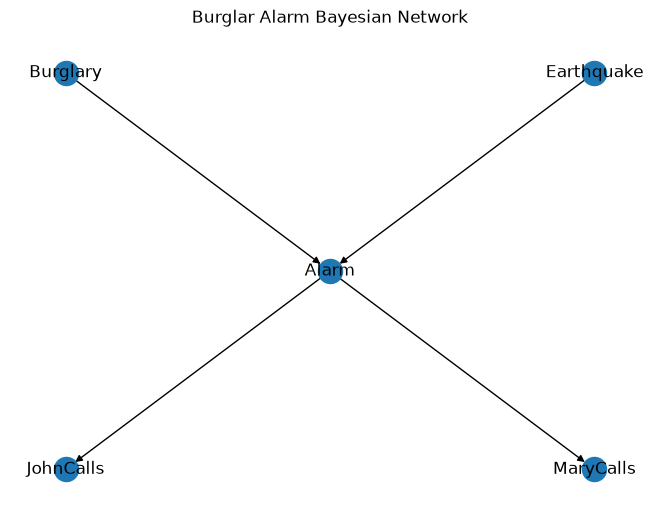

In [3]:
# Visualizes the network structure

nx.draw(
    alarm_model,
    pos={
        "Burglary": (0, 2),
        "Earthquake": (2, 2),
        "Alarm": (1, 1),
        "JohnCalls": (0, 0),
        "MaryCalls": (2, 0),
    },
    with_labels=True,

    # Additional settins as per preferences
    # node_size=3000,
    # node_color="lightyellow",
    # edgecolors="black",
    # font_size=9,
    # arrowsize=20,
)
plt.title("Burglar Alarm Bayesian Network")
plt.show()

## Defining the Conditional Probability Tables (CPTs)

Each node in the network gets a `TabularCPD` — the *prior* probabilities are defined for the root nodes (`Burglary`, `Earthquake`), while *conditional* probabilities (given every combination of the parents' states) are defined for the remaining nodes.

In [4]:
# Prior probability of a burglary taking place: P(Burglary)
cpd_burglary = TabularCPD(
    variable="Burglary",                            # The variable whose CPD is defined
    variable_card=2,                                # Cardinality/no. of states of variable "Burglary"
    values=[[0.999], [0.001]],                      # Values for the CPD table
    state_names={"Burglary": ["False", "True"]},    # Names of possible states for each variable. The order in which the states are specified should match the order in the values array. I
)

# Prior probability of an earthquake taking place: P(Earthquake)
cpd_earthquake = TabularCPD(
    variable="Earthquake",
    variable_card=2,
    values=[[0.998], [0.002]],
    state_names={"Earthquake": ["False", "True"]},
)

In [5]:
# Probability of the alarm ringing given a (Burglary, Earthquake) combination: P(Alarm | Burglary, Earthquake)

# Columns are ordered as (B=False,E=False), (B=False,E=True), (B=True,E=False), (B=True,E=True)
cpd_alarm = TabularCPD(
    variable="Alarm",
    variable_card=2,
    values=[
        [0.999, 0.71, 0.06, 0.05],  # P(Alarm=False | B, E)
        [0.001, 0.29, 0.94, 0.95],  # P(Alarm=True  | B, E)
    ],
    evidence=["Burglary", "Earthquake"],        # List of variables in evidences w.r.t. which CPD is defined
    evidence_card=[2, 2],                       # Cardinality/no. of states of variables in evidence
    state_names={
        "Alarm": ["False", "True"],
        "Burglary": ["False", "True"],
        "Earthquake": ["False", "True"],
    },
)

In [6]:
# Probability that John calls given the alarm state: P(JohnCalls | Alarm)
cpd_john = TabularCPD(
    variable="JohnCalls",
    variable_card=2,
    values=[
        [0.95, 0.10],  # P(JohnCalls=False | Alarm)
        [0.05, 0.90],  # P(JohnCalls=True  | Alarm)
    ],
    evidence=["Alarm"],
    evidence_card=[2],
    state_names={"JohnCalls": ["False", "True"], "Alarm": ["False", "True"]},
)

# Probability that Mary calls given the alarm state: P(MaryCalls | Alarm)
cpd_mary = TabularCPD(
    variable="MaryCalls",
    variable_card=2,
    values=[
        [0.99, 0.30],  # P(MaryCalls=False | Alarm)
        [0.01, 0.70],  # P(MaryCalls=True  | Alarm)
    ],
    evidence=["Alarm"],
    evidence_card=[2],
    state_names={"MaryCalls": ["False", "True"], "Alarm": ["False", "True"]},
)

In [7]:
# Attaches all the CPDs to the network

alarm_model.add_cpds(cpd_burglary, cpd_earthquake, cpd_alarm, cpd_john, cpd_mary)

# Verifies that the model structure and CPDs are consistent
# (every CPD is properly defined and their probabilities sum up to 1)
print("Model is valid:", alarm_model.check_model())

Model is valid: True


In [8]:
# Displays the CPD attached to every node of the network

for cpd in alarm_model.get_cpds():
    print(f"CPT of {cpd.variable}:")
    print(cpd)
    print()

CPT of Burglary:
+-----------------+-------+
| Burglary(False) | 0.999 |
+-----------------+-------+
| Burglary(True)  | 0.001 |
+-----------------+-------+

CPT of Earthquake:
+-------------------+-------+
| Earthquake(False) | 0.998 |
+-------------------+-------+
| Earthquake(True)  | 0.002 |
+-------------------+-------+

CPT of Alarm:
+--------------+-------------------+-----+------------------+
| Burglary     | Burglary(False)   | ... | Burglary(True)   |
+--------------+-------------------+-----+------------------+
| Earthquake   | Earthquake(False) | ... | Earthquake(True) |
+--------------+-------------------+-----+------------------+
| Alarm(False) | 0.999             | ... | 0.05             |
+--------------+-------------------+-----+------------------+
| Alarm(True)  | 0.001             | ... | 0.95             |
+--------------+-------------------+-----+------------------+

CPT of JohnCalls:
+------------------+--------------+-------------+
| Alarm            | Alarm(Fals

## Exact Inference Using Variable Elimination

`pgmpy` provides `VariableElimination` to perform exact inference — it answers a query by systematically summing out (marginalizing) the variables that are not part of the query or the evidence, following the elimination order it internally decides.

In [9]:
# Creates the Variable Elimination inference engine for the network

infer = VariableElimination(alarm_model)

**Query 1 (diagnostic reasoning):** What is the probability of a burglary given that both John and Mary called?

In [10]:
# The query 1 is formulated as P(Burglary | JohnCalls=True, MaryCalls=True)?

query_burglary = infer.query(
    variables=["Burglary"],
    evidence={"JohnCalls": "True", "MaryCalls": "True"},
)
print(query_burglary)

+-----------------+-----------------+
| Burglary        |   phi(Burglary) |
+=================+=================+
| Burglary(False) |          0.7158 |
+-----------------+-----------------+
| Burglary(True)  |          0.2842 |
+-----------------+-----------------+


**Query 2 (causal reasoning):** What is the probability that John calls given that a burglary occurred?

In [11]:
# The query 2 is formulated as P(JohnCalls | Burglary=True)?

query_john_given_burglary = infer.query(
    variables=["JohnCalls"],
    evidence={"Burglary": "True"},
)
print(query_john_given_burglary)

+------------------+------------------+
| JohnCalls        |   phi(JohnCalls) |
+==================+==================+
| JohnCalls(False) |           0.1510 |
+------------------+------------------+
| JohnCalls(True)  |           0.8490 |
+------------------+------------------+


**Query 3 (marginal prior probability):** What is the probability that the alarm rings (with no evidence)?

In [12]:
# The query 3 is formulated as P(Alarm)?

query_alarm_prior = infer.query(variables=["Alarm"])
print(query_alarm_prior)

+--------------+--------------+
| Alarm        |   phi(Alarm) |
+==============+==============+
| Alarm(False) |       0.9975 |
+--------------+--------------+
| Alarm(True)  |       0.0025 |
+--------------+--------------+


## Verifying `pgmpy` Inference Against Manual Bayes' Theorem Calculation

For sanity-check against the `pgmpy` inferences, the two-node subset **Alarm &rarr; JohnCalls** is picked and $P(\text{Alarm} = \text{True} \mid \text{JohnCalls} = \text{True})$ is computed by hand using Bayes' theorem:

$$
P(A \mid J) = \frac{P(J \mid A)\, P(A)}{P(J)}
$$

where the denominator is obtained using the law of total probability:

$$
P(J) = P(J \mid A)\, P(A) + P(J \mid \lnot A)\, P(\lnot A)
$$

The prior $P(A)$ used below is the marginal `P(Alarm)` computed by variable elimination above (Query 3), and $P(J \mid A)$, $P(J \mid \lnot A)$ come directly from the `JohnCalls` CPT defined earlier.

In [13]:
# Extracts P(Alarm=True) from the marginal computed by variable elimination (Query 3)
p_alarm_true = query_alarm_prior.get_value(Alarm="True")
p_alarm_false = query_alarm_prior.get_value(Alarm="False")

# Extracts P(JohnCalls=True | Alarm) directly from the JohnCalls CPT
p_john_given_alarm_true = cpd_john.get_value(JohnCalls="True", Alarm="True")
p_john_given_alarm_false = cpd_john.get_value(JohnCalls="True", Alarm="False")

# Law of total probability: P(JohnCalls=True)
p_john_true = (p_john_given_alarm_true * p_alarm_true) + (p_john_given_alarm_false * p_alarm_false)

# Bayes' theorem: P(Alarm=True | JohnCalls=True)
p_alarm_given_john_manual = (p_john_given_alarm_true * p_alarm_true) / p_john_true

print(f"P(Alarm=True)              = {p_alarm_true:.6f}")
print(f"P(JohnCalls=True)          = {p_john_true:.6f}")
print(f"P(Alarm=True | JohnCalls=True), manual Bayes' theorem = {p_alarm_given_john_manual:.6f}")

P(Alarm=True)              = 0.002516
P(JohnCalls=True)          = 0.052139
P(Alarm=True | JohnCalls=True), manual Bayes' theorem = 0.043438


In [14]:
# Computes the same query using pgmpy's variable elimination for comparison
# P(Alarm | JohnCalls=True)

query_alarm_given_john = infer.query(variables=["Alarm"], evidence={"JohnCalls": "True"})
p_alarm_given_john_pgmpy = query_alarm_given_john.get_value(Alarm="True")

print(query_alarm_given_john)
print(f"P(Alarm=True | JohnCalls=True), pgmpy variable elimination = {p_alarm_given_john_pgmpy:.6f}")

+--------------+--------------+
| Alarm        |   phi(Alarm) |
+==============+==============+
| Alarm(False) |       0.9566 |
+--------------+--------------+
| Alarm(True)  |       0.0434 |
+--------------+--------------+
P(Alarm=True | JohnCalls=True), pgmpy variable elimination = 0.043438


In [15]:
# Compares the manually computed result against pgmpy's variable elimination result

difference = abs(p_alarm_given_john_manual - p_alarm_given_john_pgmpy)
print(f"Manual Bayes' theorem result : {p_alarm_given_john_manual:.6f}")
print(f"pgmpy inference result      : {p_alarm_given_john_pgmpy:.6f}")
print(f"Absolute difference         : {difference:.10f}")

assert difference < 1e-9, "Manual calculation does not match pgmpy's inference result!"
print("\nThe manual Bayes' theorem calculation matches pgmpy's exact inference result.")

Manual Bayes' theorem result : 0.043438
pgmpy inference result      : 0.043438
Absolute difference         : 0.0000000000

The manual Bayes' theorem calculation matches pgmpy's exact inference result.
